# Step 1: Rigid Registration

Time-lapse microscopy movies almost always contain some amount of **stage
drift**: the field of view shifts by a pixel or few from frame to frame due
to mechanical vibration, thermal expansion, or the stage motor itself.
Before segmenting or tracking cells, it helps to remove this drift so that a
cell sitting still in the dish also sits still in the image.

`cellmate.registration.rigid` does this with a classic intensity-based rigid
(translation-only) registration: for each frame it estimates the 2D shift
that best aligns a chosen **reference channel** with the previous frame
(using [SimpleITK](https://simpleitk.org/)'s regular-step-gradient-descent
optimizer and Mattes mutual information as the similarity metric), then
applies that same shift to *every* channel of that frame.

This notebook:
1. loads one of the package's example movies,
2. independently measures how much drift is actually present,
3. runs `rigid()` on it,
4. re-measures the drift to confirm it worked, and
5. saves the registered movie.

A command-line equivalent (`01_rigid_registration.py`) is included in this
same folder for batch-processing many files without a notebook.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread, imsave
from skimage.registration import phase_cross_correlation

# Make sure `cellmate` is importable regardless of where Jupyter was launched
# from: walk up from the current directory until we find the repo root
# (identified by containing a `cellmate` package folder).
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cellmate").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cellmate.registration import rigid

print("cellmate loaded from:", REPO_ROOT / "cellmate")

cellmate loaded from: /home/wlli/project/CellMate/cellmate


## 1. Load the example movie

In [2]:
input_path = REPO_ROOT / "demo" / "yav2104yav2105_mating_example_01.tif"
image = imread(str(input_path))
print("as stored on disk:", image.shape, image.dtype)

# `rigid()` expects [Time, Channel, Height, Width]. This particular file was
# saved with channels last ([T, H, W, C]) -- a common convention -- so we
# move the channel axis into place. If your own data is already
# [T, C, H, W] you can skip this step.
image = np.moveaxis(image, -1, 1)
print("as [T, C, H, W]:        ", image.shape, image.dtype)

n_frames, n_channels, height, width = image.shape

as stored on disk: (145, 250, 250, 3) uint16
as [T, C, H, W]:         (145, 3, 250, 250) uint16


## 2. Quantify the drift (before)

Rather than just trust that registration "did something", let's measure the
drift independently with `skimage.registration.phase_cross_correlation`
(sub-pixel image cross-correlation) applied to channel 0. We track the shift
of every 5th frame relative to frame 0.

In [3]:
def drift_curve(channel_stack, step=5):
    """Sub-pixel shift of every `step`-th frame relative to frame 0."""
    reference = channel_stack[0].astype(float)
    frames, shifts = [], []
    for t in range(0, channel_stack.shape[0], step):
        shift, *_ = phase_cross_correlation(reference, channel_stack[t].astype(float),
                                            upsample_factor=10)
        frames.append(t)
        shifts.append(np.linalg.norm(shift))
    return np.array(frames), np.array(shifts)

reference_channel = 0
frames_before, drift_before = drift_curve(image[:, reference_channel])
print("max drift before registration: %.1f px" % drift_before.max())

max drift before registration: 11.7 px


## 3. Run rigid registration

Key parameters (all forwarded to SimpleITK's optimizer):

| parameter | meaning |
|---|---|
| `reference_channel` | which channel is used to *estimate* the shift (the shift is then applied to all channels) |
| `maxStep` / `minStep` | largest / smallest step the optimizer takes each iteration; smaller `minStep` = more precise but slower |
| `numberOfIterations` | optimizer iteration budget per frame |
| `relaxationFactor` | how aggressively the step size shrinks when the optimizer overshoots |
| `tolerance` | gradient-magnitude convergence tolerance |

The defaults below work well for this dataset; for noisier or faster-moving
data you may need a larger `maxStep` (see the "tips" section at the end).

In [4]:
%%time
moved = rigid(
    image,
    reference_channel=reference_channel,
    maxStep=1.0,
    minStep=0.0001,
    numberOfIterations=1000,
    relaxationFactor=0.05,
)
print(moved.shape, moved.dtype)

(145, 3, 250, 250) uint16
CPU times: user 2min 5s, sys: 3.83 s, total: 2min 9s
Wall time: 12.9 s


## 4. Verify the drift is reduced (after)

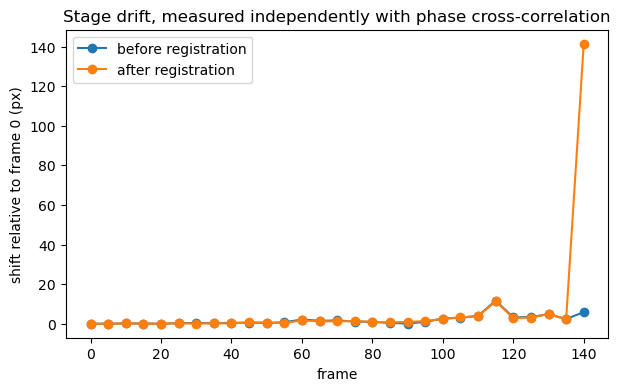

In [5]:
frames_after, drift_after = drift_curve(moved[:, reference_channel])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(frames_before, drift_before, "o-", label="before registration")
ax.plot(frames_after, drift_after, "o-", label="after registration")
ax.set_xlabel("frame")
ax.set_ylabel("shift relative to frame 0 (px)")
ax.set_title("Stage drift, measured independently with phase cross-correlation")
ax.legend()
plt.show()

For most frames the registered drift sits much closer to zero. Registration
is not magic, though: a handful of frames can still register poorly (for
example if the sample changes too much between frames for the optimizer to
find a good alignment, such as around a fast-moving mating event). It is
good practice to always plot a drift curve like this one -- computed with a
method *independent* of the registration itself -- as a sanity check rather
than assuming the output is correct. Frames that remain outliers are worth
re-running with different parameters or excluding from downstream analysis.

## 5. Save the registered movie

In [6]:
output_path = REPO_ROOT / "demo" / "quickstart" / "outputs" / "01_rigid_registration_demo.tif"
output_path.parent.mkdir(parents=True, exist_ok=True)
imsave(str(output_path), moved.astype(np.uint16), imagej=True, check_contrast=False)
print("saved to", output_path)

saved to /home/wlli/project/CellMate/demo/quickstart/outputs/01_rigid_registration_demo.tif


## Parameter tuning tips

* **`reference_channel`** should be whichever channel has the most stable,
  high-contrast structure to lock onto -- often a brightfield/DIC channel
  rather than a dim fluorescence channel.
* If registration is consistently *under*-correcting (drift curve barely
  changes), try a larger `maxStep` and/or more `numberOfIterations`.
* If registration is *unstable* (occasional huge, wrong shifts, as discussed
  above), try tightening `minStep`/`tolerance`, or pre-smoothing very noisy
  channels before registering.
* For a full, real acquisition (hundreds of frames, larger drift),
  `demo/tmp/00_example_code_rigid_registration.ipynb` shows a batch loop
  over many files using `maxStep=10, minStep=0.5, relaxationFactor=0.1`.

## Command-line equivalent

```bash
python 01_rigid_registration.py \
    --input ../yav2104yav2105_mating_example_01.tif \
    --output outputs/01_rigid_registration_demo.tif \
    --channel-last \
    --reference-channel 0
```

Run `python 01_rigid_registration.py --help` for the full list of options.